In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import svm
from math import log, sqrt
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, log_loss, precision_recall_curve, accuracy_score, precision_score, recall_score, f1_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
data = pd.read_csv("Dataset_Day7.csv")

# Missing data treatment
print('Before Missing Data Treatment')
for col in ['Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction'] :
    print(col,' = ',len(data[col][data[col]==0]))
for col in ['Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction'] :
    data[col][data[col]==0] = data[col].median()
print('\nAfter Missing Data Treatment')
for col in ['Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction'] :
    print(col,' = ',len(data[col][data[col]==0]))

outlier = pd.DataFrame(columns = ["Pregnancies","Glucose","BloodPressure","BMI","Age"])
temp = data.drop('Outcome',axis=1)
for col in ["Pregnancies","Glucose","BloodPressure","BMI","Age"]:
    Q1 = temp[col].quantile(0.25)
    Q3 = temp[col].quantile(0.75)
    IQR = Q3 - Q1
    UpperBound = Q3 + 1.5*IQR
    LowerBound = Q1 - 1.5*IQR
    outlier[col] = temp[col][(temp[col]<=LowerBound)|(temp[col]>=UpperBound)]

OutlierFreeData = data.drop(outlier.index,axis=0)
print("\nno. of Outlier",len(outlier), "\n% of Outlier = ", str(len(outlier)/len(data)*100))

Before Missing Data Treatment
Glucose  =  5
BloodPressure  =  35
BMI  =  11
DiabetesPedigreeFunction  =  0

After Missing Data Treatment
Glucose  =  0
BloodPressure  =  0
BMI  =  0
DiabetesPedigreeFunction  =  0

no. of Outlier 4 
% of Outlier =  0.5208333333333333


C:\Users\nikhi\AppData\Local\Temp\ipykernel_6296\3315839205.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data[col][data[col]==0] = data[col].median()


Model Performance metrics are as below :-

Accuracy is 0.8260869565217391
Precision is 0.8305084745762712
Recall is 0.620253164556962
F1-Score is 0.7101449275362318
[[141  10]
 [ 30  49]]


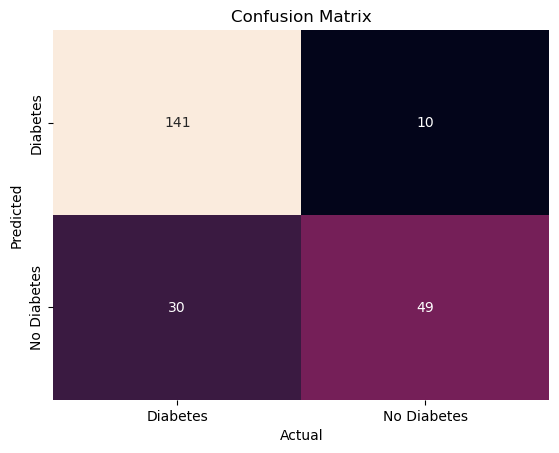

In [3]:
# Spliting of data 7:3
X = OutlierFreeData.drop("Outcome",axis=1)
y = OutlierFreeData["Outcome"]
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.30, random_state=44)

kernel_values =['linear', 'poly', 'rbf', 'sigmoid']

model = svm.SVC(kernel=kernel_values[0], C = 1, gamma =0.1)
model.fit(X_train,y_train)
y_pred = model.predict(X_test)

print("Model Performance metrics are as below :-\n")
print("Accuracy is "+str(accuracy_score(y_test,y_pred)))
print("Precision is "+str(precision_score(y_test,y_pred)))
print("Recall is "+str(recall_score(y_test,y_pred)))
print("F1-Score is "+str(f1_score(y_test,y_pred)))

cm = confusion_matrix(y_test,y_pred)
print(cm)
ax = plt.subplot()
sns.heatmap(cm,annot = True , fmt = "d" , cbar = False , ax = ax)
ax.set_xlabel('Actual')
ax.set_ylabel('Predicted')
ax.set_title('Confusion Matrix')
ax.xaxis.set_ticklabels(['Diabetes','No Diabetes'])
ax.yaxis.set_ticklabels(['Diabetes','No Diabetes'])
plt.show()

In [ ]:
C = [0.001,0.01,0.1,1,10,100,1000]
gamma= [0.1, 1/len(X)]
kernel =['linear', 'poly', 'rbf', 'sigmoid']
df = pd.DataFrame(columns=['Kernel Type','C','Gamma','Precision','Recall','Accuracy','F1-Score'])
for k in kernel:
    for c in C:
        for g in gamma:
            model = svm.SVC(kernel=k, C=c, gamma = g)
            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            df = pd.concat([pd.DataFrame([[k, c, g, precision_score(y_test,y_pred), recall_score(y_test,y_pred), accuracy_score(y_test,y_pred),f1_score(y_test,y_pred)]], columns=df.columns), df], ignore_index=True)

# display(PerfData.head(10))
display(df[df['F1-Score'] == max(df['F1-Score'])])

Name - Nikhil Khatri

SIC - 21BCSA92